In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 

In [30]:
train = pd.read_csv("../data/raw/train.csv")

print("Training documents:", len(train))
print("Total documents:", 45615 + 2000 + 12284)

Training documents: 45615
Total documents: 59899


In [31]:
train["word_count"] = train["text"].apply(
    lambda text: len(str(text).split())
)

print(
    "Average words per tweet:",
    train["word_count"].mean()
)

print(
    "Maximum words:",
    train["word_count"].max()
)

Average words per tweet: 19.23744382330374
Maximum words: 35


In [32]:
print(train["label_name"].value_counts())

label_name
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64


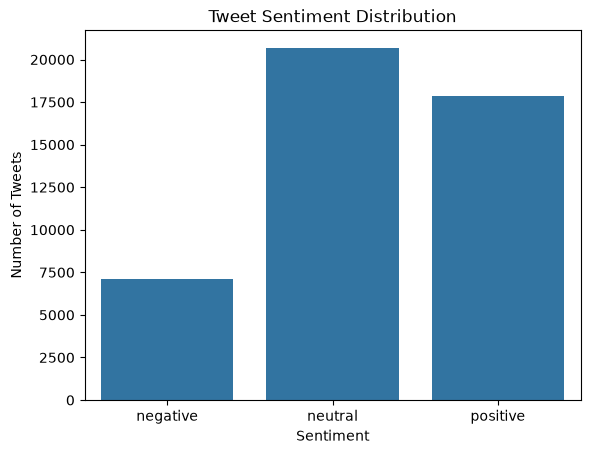

In [33]:
sns.countplot(
    data=train,
    x="label_name",
    order=["negative", "neutral", "positive"]
)

plt.title("Tweet Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")
plt.show()

In [34]:
from nltk.tokenize import TweetTokenizer

tokenizer = TweetTokenizer()

sample = train.sample(
    n=1000,
    random_state=42
)

all_tokens = []

for text in sample["text"]:
    tokens = tokenizer.tokenize(str(text).lower())
    all_tokens.extend(tokens)

total_tokens = len(all_tokens)
unique_types = len(set(all_tokens))

print("Total tokens:", total_tokens)
print("Unique types:", unique_types)
print("Vocabulary size:", unique_types)

Total tokens: 22618
Unique types: 4903
Vocabulary size: 4903


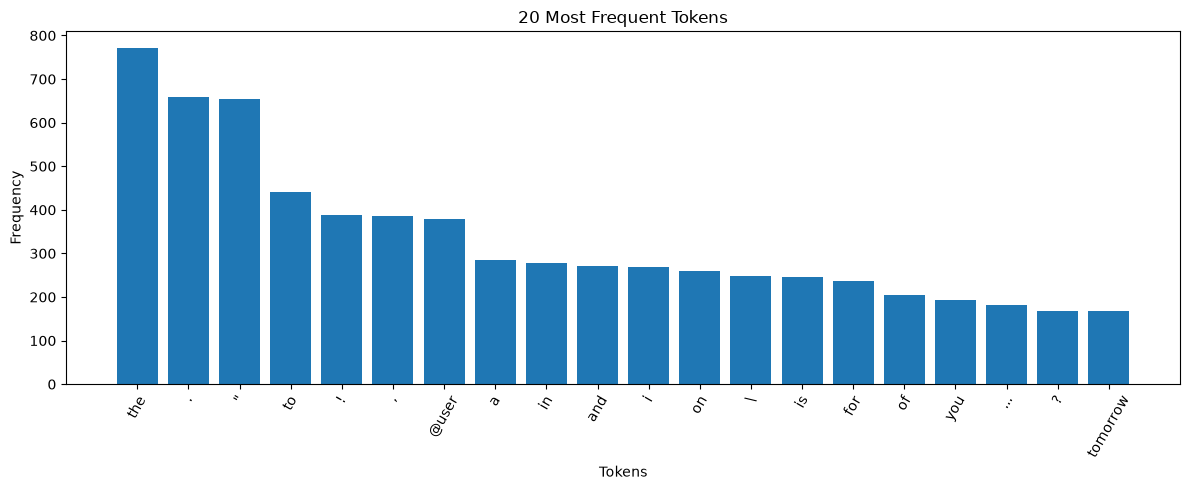

In [35]:
from collections import Counter

word_counts = Counter(all_tokens)

most_common = word_counts.most_common(20)

words, frequencies = zip(*most_common)

plt.figure(figsize=(12, 5))

plt.bar(words, frequencies)

plt.xticks(rotation=60)
plt.title("20 Most Frequent Tokens")
plt.xlabel("Tokens")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

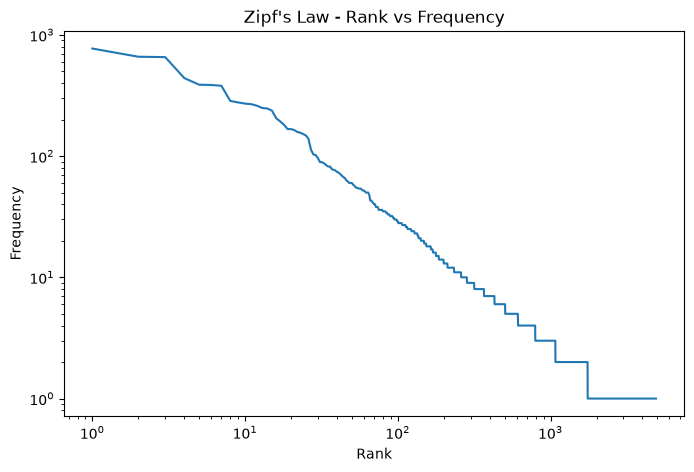

In [36]:
frequencies = sorted(
    word_counts.values(),
    reverse=True
)

plt.figure(figsize=(8, 5))

plt.loglog(
    range(1, len(frequencies) + 1),
    frequencies
)

plt.title("Zipf's Law - Rank vs Frequency")
plt.xlabel("Rank")
plt.ylabel("Frequency")

plt.show()

In [37]:
examples = train.sample(
    n=5,
    random_state=42
)

for index, row in examples.iterrows():
    print("Tweet:", row["text"])
    print("Label:", row["label_name"])
    print("-" * 80)

Tweet: I forgot all about Ice Cube being in the movie First Sunday. I think I seen this shit in the theaters.
Label: negative
--------------------------------------------------------------------------------
Tweet: playoffs are finally set. Chardon plays warren howland in the 1st round. if we win\u002c we play the winner of kenston v. tallmadge.
Label: neutral
--------------------------------------------------------------------------------
Tweet: Are we just going to ignore the fact that Ice Cube got his ass whoop by Ricky Smiley at the beginning of Friday After Next???
Label: neutral
--------------------------------------------------------------------------------
Tweet: If you live in the South Orlando area\u002c be on the lookout. @user has its 6th site opening on October 30th near the Florida Mall!
Label: neutral
--------------------------------------------------------------------------------
Tweet: First record of Colin Baker at the BBC: BBC2 serial The Roads to Freedom. Part 5 - sh